# Proyecto Parte 1 - Clasificación de sentimiento en reseñas
**Curso Aprendizaje de Máquina 2026-20 - Grupo 31**

El objetivo es predecir si una reseña de producto en español es `negativo`, `neutral` o `positivo`. En esta primera parte solo usamos modelos clásicos de scikit-learn y representaciones de texto tipo bolsa de palabras / TF-IDF / n-gramas (nada de redes neuronales ni embeddings preentrenados).

Orden del notebook:
1. Carga y exploración de los datos
2. Preprocesamiento
3. Modelos base con bolsa de palabras
4. Análisis de errores: el orden importa
5. Segmentación en cláusulas y conectores
6. Modelo de polaridad por cláusula
7. Modelo final (stacking) y ajuste
8. Entrenamiento final, guardado del modelo y archivo de envío
9. Conclusiones

## 1. Carga y exploración de los datos

In [1]:
import re
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

SEMILLA = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
print('scikit-learn', sklearn.__version__)

scikit-learn 1.9.0


In [2]:
train = pd.read_csv('train.csv')
evaluacion = pd.read_csv('eval.csv')
print(train.shape, evaluacion.shape)
train.head()

(12000, 3) (3000, 2)


,id,text,label
0,0,Lo pedí un martes por la noche y me llegó al d...,neutral
1,1,Se lo compré a un familiar después de pensarla...,positivo
2,2,Lo pedí a mediados de mes y me llegó en tres d...,negativo
3,3,Compré esto en línea y llegó en unos tres días...,negativo
4,4,Compré este kit el mes pasado porque necesitab...,positivo


In [3]:
print('Nulos train:', train.isna().sum().sum(), '| Nulos eval:', evaluacion.isna().sum().sum())
print('Textos duplicados en train:', train.text.duplicated().sum())
print()
print(train.label.value_counts())

Nulos train: 0 | Nulos eval: 0
Textos duplicados en train: 0

label
positivo    4212
negativo    4212
neutral     3576
Name: count, dtype: int64


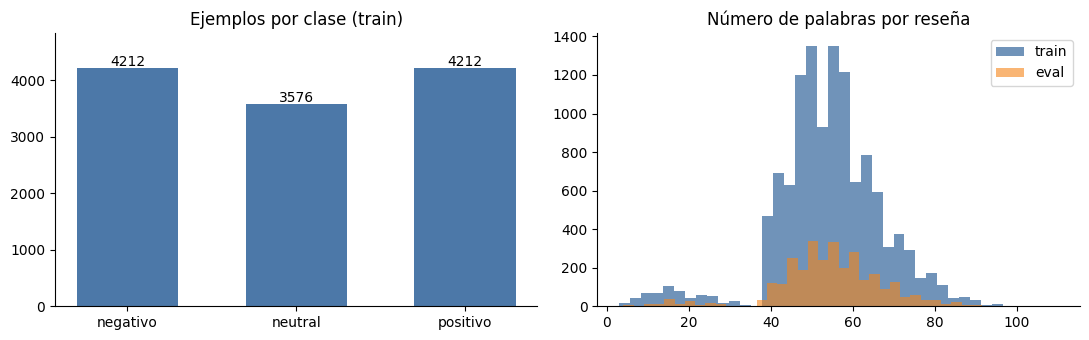

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
conteo = train.label.value_counts().reindex(['negativo', 'neutral', 'positivo'])
ax[0].bar(conteo.index, conteo.values, color='#4C78A8', width=0.6)
ax[0].set_title('Ejemplos por clase (train)')
for i, v in enumerate(conteo.values):
    ax[0].text(i, v + 50, str(v), ha='center')
ax[0].set_ylim(0, conteo.max() * 1.15)

ax[1].hist(train.text.str.split().str.len(), bins=40, color='#4C78A8', alpha=0.8, label='train')
ax[1].hist(evaluacion.text.str.split().str.len(), bins=40, color='#F58518', alpha=0.6, label='eval')
ax[1].set_title('Número de palabras por reseña')
ax[1].legend()
for a in ax:
    a.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

Las clases están bastante balanceadas (neutral un poco por debajo), así que la accuracy es una métrica razonable y además es la que usa Kaggle. Las reseñas son cortas (~54 palabras en promedio) y la distribución de longitudes de train y eval es prácticamente igual.

Miramos algunos ejemplos de cada clase:

In [5]:
pd.set_option('display.max_colwidth', None)
for etiqueta in ['negativo', 'neutral', 'positivo']:
    print('=====', etiqueta)
    for t in train[train.label == etiqueta].text.sample(3, random_state=1):
        print('-', t)
    print()

===== negativo
- Les cuento como me fue con esta compra. Llego en unos cuatro dias a mi casa aqui en Guadalajara y la compre en color azul, que al final el color es igual al de las fotos. La uso casi todos los dias para salir a correr por las mananas antes del trabajo, y por cierto la autonomia se mantuvo redonda al final de cuentas, o sea aguanta lo que dice en la descripcion. Lei las instrucciones y segun tiene sellado para sumergirla, pero la resistencia al agua me resulto ser defectuosa con el tiempo.
- Le puse tres pilas AAA comunes y arrancó sin problema, lo compré hace unos meses para llevar de acá para allá. La verdad, la batería se mantuvo buenísima después de tanto trajín, eso me gustó. Eso sí, la portabilidad se ve floja en mi experiencia, no la puedo mover de un lado a otro con la facilidad que yo pensaba.
- Me animo a comentar porque la pedí hace un par de semanas por internet y llegó en tres días. La tapa no vale lo que cuesta, la verdad. Por otro lado, el manual de uso s

Cosas que notamos al leer las reseñas:
- Casi todas empiezan con frases de "relleno" sobre la compra y el envío (*"lo pedí un martes y llegó en tres días"*) que no dicen nada del sentimiento.
- Las neutrales básicamente son solo relleno / datos del producto.
- Muchas positivas y negativas tienen **opiniones mezcladas**: una cosa buena y otra mala. Ahí la etiqueta depende de cuál "gana".
- Hay textos sin tildes y algunos errores de tipeo (*"caabeza"*, *"ojoos"*).

Revisamos lo de las tildes en los dos archivos:

In [6]:
con_tilde = lambda s: s.str.contains('[áéíóúñ]', case=False, regex=True).mean()
print(f'Reseñas con al menos una tilde/ñ -> train: {con_tilde(train.text):.1%} | eval: {con_tilde(evaluacion.text):.1%}')

Reseñas con al menos una tilde/ñ -> train: 68.7% | eval: 68.6%


Alrededor del 31% de las reseñas (en ambos archivos) vienen sin tildes. Si no normalizamos, "llegó" y "llego" serían palabras distintas para el vectorizador, así que quitamos las tildes.

## 2. Preprocesamiento

- Pasamos todo a minúsculas.
- Quitamos tildes y diacríticos (la ñ queda como n).
- **No** quitamos stopwords: palabras como *no*, *ni*, *pero*, *aunque* son justamente las que cambian el sentimiento.
- No hacemos stemming; lo probamos rápido al principio y no ayudaba, y con TF-IDF + bigramas no hace mucha falta.

In [7]:
def normalizar(texto):
    texto = unicodedata.normalize('NFKD', texto.lower())
    return ''.join(c for c in texto if not unicodedata.combining(c))

train['norm'] = train.text.map(normalizar)
y = train.label.values
train.norm[1]

'se lo compre a un familiar despues de pensarla varias semanas, llego en unos cuatro dias a mi casa. la verdad sea dicha, el soporte tecnico me resulto incumplidor para lo que necesitaba, tardaban harto en contestar. al final de cuentas, la nitidez de la imagen se mantuvo decente en el uso diario.'

## 3. Modelos base con bolsa de palabras

Empezamos con lo visto en clase: bolsa de palabras y TF-IDF con distintos clasificadores. Todo se evalúa con validación cruzada estratificada de 5 folds sobre train.

In [8]:
def evaluar(nombre, modelo, X, resultados):
    s = cross_val_score(modelo, X, y, cv=CV, n_jobs=-1)
    resultados.append({'modelo': nombre, 'accuracy': s.mean(), 'std': s.std()})
    print(f'{nombre:45s} {s.mean():.4f} (+/- {s.std():.4f})')

res_base = []
evaluar('BoW + MultinomialNB', make_pipeline(CountVectorizer(), MultinomialNB()), train.norm, res_base)
evaluar('TF-IDF unigramas + LogReg',
        make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=3000, C=10)), train.norm, res_base)
evaluar('TF-IDF 1-2 gramas + LogReg',
        make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2),
                      LogisticRegression(max_iter=3000, C=10)), train.norm, res_base)
evaluar('TF-IDF 1-3 gramas + LinearSVC',
        make_pipeline(TfidfVectorizer(ngram_range=(1, 3), sublinear_tf=True, min_df=2), LinearSVC(C=0.5)),
        train.norm, res_base)
evaluar('TF-IDF char 2-5 gramas + LinearSVC',
        make_pipeline(TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), sublinear_tf=True, min_df=2),
                      LinearSVC(C=0.5)), train.norm, res_base)

BoW + MultinomialNB                           0.6992 (+/- 0.0069)


TF-IDF unigramas + LogReg                     0.7356 (+/- 0.0063)


TF-IDF 1-2 gramas + LogReg                    0.7408 (+/- 0.0076)


TF-IDF 1-3 gramas + LinearSVC                 0.7275 (+/- 0.0098)


TF-IDF char 2-5 gramas + LinearSVC            0.7371 (+/- 0.0052)


El mejor de estos es TF-IDF con unigramas y bigramas + regresión logística, con ~74%. Los n-gramas de caracteres (que deberían ayudar con los errores de tipeo) quedan parecidos pero no mejores. Con este modelo hicimos el **primer envío** a Kaggle.

In [9]:
import os
os.makedirs('envios', exist_ok=True)
eval_norm = evaluacion.text.map(normalizar)

def guardar_envio(pred, nombre):
    sub = pd.DataFrame({'id': evaluacion.id, 'answer': pred})
    sub.to_csv(f'envios/{nombre}.csv', index=False)
    print(f'envios/{nombre}.csv', dict(sub.answer.value_counts()))

modelo_base = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2),
                            LogisticRegression(max_iter=3000, C=10))
modelo_base.fit(train.norm, y)
guardar_envio(modelo_base.predict(eval_norm), '01_tfidf_logreg')

envios/01_tfidf_logreg.csv {'negativo': np.int64(1109), 'positivo': np.int64(1053), 'neutral': np.int64(838)}


## 4. Análisis de errores: el orden importa

74% no está mal, pero queríamos entender en qué se equivoca. Sacamos las predicciones fuera de fold y miramos la matriz de confusión y algunos errores.

In [10]:
pred_base = cross_val_predict(modelo_base, train.norm, y, cv=CV, n_jobs=-1)
print(classification_report(y, pred_base, digits=3))
print(confusion_matrix(y, pred_base, labels=['negativo', 'neutral', 'positivo']))

              precision    recall  f1-score   support

    negativo      0.640     0.627     0.634      4212
     neutral      0.980     0.998     0.989      3576
    positivo      0.633     0.636     0.635      4212

    accuracy                          0.741     12000
   macro avg      0.751     0.754     0.752     12000
weighted avg      0.739     0.741     0.740     12000

[[2642   25 1545]
 [   1 3568    7]
 [1485   47 2680]]


In [11]:
errores = train[(pred_base != y) & (y != 'neutral')].assign(pred=pred_base[(pred_base != y) & (y != 'neutral')])
for r in errores.sample(6, random_state=3).itertuples():
    print(f'[real: {r.label} | predicho: {r.pred}]')
    print(r.text, '\n')

[real: negativo | predicho: positivo]
Lo pedí a mediados de mes y llegó en cuatro días a casa. Está disponible en dos tamaños, yo agarré el pequeño para llevarlo en la mochila. Por otro lado, la duración de la carga se ve superior comparado con otros que he tenido antes. Lo compré porque lo necesitaba para un viaje, aunque igual el diseño se mantuvo débil para el precio que tiene. 

[real: negativo | predicho: positivo]
Lo compré a mediados de año y llegó en unos cuatro días a mi casa. El botón de encendido luce durable en general, eso sí hay que reconocerlo. Lo he estado usando casi a diario desde que me llegó, más que nada en las tardes. Aun así, la pantalla quedó mediocre en mi experiencia. 

[real: negativo | predicho: positivo]
Me llegó el martes por la mañana, dos días después de pedirlo. Lo uso a diario desde entonces, ya le agarré el tranco. La pantalla me pareció bien lograda desde que lo estrené, nítida para lo que necesito. Eso sí, el manual de uso me resultó incómodo según 

Lo neutral lo separa casi perfecto. El problema está entre positivo y negativo, y en los ejemplos se ve por qué: la reseña tiene una cosa buena y una mala, y la bolsa de palabras ve las dos con el mismo peso sin importar el orden ni el conector que las une. Muchas veces la opinión que **va al final** es la que define la etiqueta (*"..., pero al final la batería es potente"* -> positivo).

Para probar esa idea entrenamos el mismo modelo pero solo con la **última oración** de cada reseña, y también combinando el texto completo con la última oración (dos TF-IDF distintos concatenados):

In [12]:
def oraciones(texto):
    return [o.strip() for o in re.split(r'[.!?;]+', texto) if o.strip()]

vistas = pd.DataFrame({'completo': train.norm})
vistas['ult_oracion'] = [(oraciones(t) or [t])[-1] for t in train.norm]
vistas['pri_oracion'] = [(oraciones(t) or [t])[0] for t in train.norm]

def tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2)

def modelo_vistas(columnas, C=10):
    ct = ColumnTransformer([(c, tfidf(), c) for c in columnas])
    return make_pipeline(ct, LogisticRegression(max_iter=3000, C=C))

res_orden = []
evaluar('solo primera oración', modelo_vistas(['pri_oracion']), vistas, res_orden)
evaluar('solo última oración', modelo_vistas(['ult_oracion']), vistas, res_orden)
evaluar('texto completo + última oración', modelo_vistas(['completo', 'ult_oracion']), vistas, res_orden)

solo primera oración                          0.5129 (+/- 0.0059)


solo última oración                           0.8547 (+/- 0.0036)


texto completo + última oración               0.8852 (+/- 0.0039)


Esto confirma lo que sospechábamos: **solo la última oración ya le gana por 11 puntos a todo el texto**, y combinando las dos llegamos a ~88.5%. La primera oración casi no sirve (es relleno del envío). Este fue el **segundo envío**.

In [13]:
eval_vistas = pd.DataFrame({'completo': eval_norm})
eval_vistas['ult_oracion'] = [(oraciones(t) or [t])[-1] for t in eval_norm]

m2 = modelo_vistas(['completo', 'ult_oracion']).fit(vistas, y)
guardar_envio(m2.predict(eval_vistas), '02_completo_mas_ultima_oracion')

envios/02_completo_mas_ultima_oracion.csv {'negativo': np.int64(1076), 'positivo': np.int64(1074), 'neutral': np.int64(850)}


## 5. Segmentación en cláusulas y conectores

La última oración a veces contiene las dos opiniones juntas (*"el soporte técnico luce pésimo, aunque al final la resolución me resultó rapidísima"*), y otras veces la última oración es relleno y la opinión está antes. Así que en vez de oraciones queremos partir el texto en **cláusulas**, cortando también en los conectores.

Para saber qué conectores usar contamos con qué palabras empiezan las oraciones (sin contar la primera):

In [14]:
inicios = Counter()
for t in train.norm:
    for o in oraciones(t)[1:]:
        inicios[' '.join(o.split(',')[0].split()[:3])] += 1
pd.DataFrame(inicios.most_common(30), columns=['inicio de oración', 'veces'])

,inicio de oración,veces
0,eso si,1514
1,aun asi,723
2,por otro lado,714
3,la verdad,640
4,por cierto,599
5,de paso,568
6,viene en color,409
7,trae garantia de,398
8,lo uso en,389
9,con todo,363


Entre lo más frecuente aparecen conectores como *eso sí, aun así, por otro lado, por cierto, de paso, con todo, además, al final, a fin de cuentas, sin embargo, en fin*. Armamos una lista con esos y con *pero / aunque* (que suelen aparecer en medio de la oración) y una función que corta el texto en cláusulas guardando qué conector las introduce.

In [15]:
CONECTORES = ['pero al final', 'aunque al final', 'a fin de cuentas', 'al final de cuentas',
              'al final', 'aun asi', 'sin embargo', 'no obstante', 'con todo', 'eso si',
              'por otro lado', 'por cierto', 'de paso', 'ademas', 'ah, y', 'ahora', 'en fin',
              'total que', 'lo que si', 'pero', 'aunque']
CONECTORES = sorted(CONECTORES, key=len, reverse=True)  # primero los más largos
PATRON_CON = re.compile(r'\b(' + '|'.join(re.escape(c) for c in CONECTORES) + r')\b')
ETIQUETAS_CON = ['ini'] + [c.replace(' ', '_').replace(',', '') for c in CONECTORES]


def segmentar(texto):
    # devuelve [(conector, clausula), ...]; conector = '_' si la cláusula no empieza con uno
    salida = []
    for oracion in oraciones(texto):
        inicio, con = 0, '_'
        for m in PATRON_CON.finditer(oracion):
            trozo = oracion[inicio:m.start()].strip(' ,')
            if trozo:
                salida.append((con, trozo))
            con = m.group(1).replace(' ', '_').replace(',', '')
            inicio = m.end()
        trozo = oracion[inicio:].strip(' ,')
        if trozo:
            salida.append((con, trozo))
    return salida or [('_', texto)]


def conector_de(segs, j):
    # el conector que "manda" sobre la cláusula j es el último que apareció antes de ella
    for k in range(j, -1, -1):
        if segs[k][0] != '_':
            return segs[k][0]
    return 'ini'


segmentar(train.norm[2])

[('_',
  'lo pedi a mediados de mes y me llego en tres dias, en su caja normal sin nada fuera de lo comun'),
 ('_', 'lo uso en la oficina casi a diario desde entonces'),
 ('_', 'el diseno se sintio durable desde el primer dia'),
 ('aun_asi', 'la relacion calidad-precio se ve desagradable con el tiempo')]

In [16]:
segs_train = [segmentar(t) for t in train.norm]
vistas['ult_clausula'] = [s[-1][1] for s in segs_train]
vistas['ult_2_clausulas'] = [' '.join(c for _, c in s[-2:]) for s in segs_train]
vistas['seg_mitad'] = [' '.join(t.split()[len(t.split()) // 2:]) for t in train.norm]

evaluar('solo última cláusula', modelo_vistas(['ult_clausula']), vistas, res_orden)
evaluar('completo + última oración + última cláusula',
        modelo_vistas(['completo', 'ult_oracion', 'ult_clausula']), vistas, res_orden)

solo última cláusula                          0.8595 (+/- 0.0048)


completo + última oración + última cláusula   0.8912 (+/- 0.0022)


Usar la última cláusula sube un poco más (~89%). Con esto hicimos el **tercer envío**.

In [17]:
segs_eval = [segmentar(t) for t in eval_norm]
eval_vistas['ult_clausula'] = [s[-1][1] for s in segs_eval]
m3 = modelo_vistas(['completo', 'ult_oracion', 'ult_clausula']).fit(vistas, y)
guardar_envio(m3.predict(eval_vistas), '03_completo_ultima_oracion_ultima_clausula')

envios/03_completo_ultima_oracion_ultima_clausula.csv {'negativo': np.int64(1073), 'positivo': np.int64(1070), 'neutral': np.int64(857)}


### ¿El conector decide quién gana?

Quisimos ver si el conector que une dos opiniones opuestas determina cuál de las dos define la etiqueta. Para eso necesitamos saber la polaridad de cada cláusula, lo cual hacemos en la siguiente sección; el resultado de ese análisis está en la sección 6. Adelantamos la idea: con *aun así, al final, con todo, sin embargo, pero* gana la segunda opinión prácticamente siempre, mientras que con *por otro lado* o *por cierto* queda más o menos 50/50. Esa interacción (conector x polaridad x posición) **no la puede representar un modelo lineal sobre bolsa de palabras**, por eso los modelos anteriores se estancan alrededor de 89%.

## 6. Modelo de polaridad por cláusula

La idea es tener un clasificador que diga, para cada cláusula, si es negativa, neutral (relleno) o positiva. El problema es que **no tenemos etiquetas por cláusula**, solo por reseña.

Primer intento (no funcionó bien): que cada cláusula herede la etiqueta de su reseña. Así la frase de relleno sí aprende a ser neutral, pero en una reseña negativa del tipo *"el diseño se sintió durable. Aun así, la relación calidad-precio se ve desagradable"* la cláusula "durable" queda etiquetada como negativa, y el modelo aprende polaridades ruidosas.

Lo que hicimos fue un entrenamiento iterativo (parecido a aprendizaje con instancias múltiples):
1. Entrenamos con la etiqueta heredada (TF-IDF + regresión logística sobre cláusulas).
2. Para cada reseña positiva/negativa nos quedamos solo con la cláusula que más apoya la etiqueta del documento, y con las cláusulas que el modelo ya ve claramente con la polaridad contraria (esas se etiquetan con la polaridad contraria). Las cláusulas de reseñas neutrales se quedan como neutrales.
3. Reentrenamos con ese nuevo conjunto y repetimos 3 veces.

In [18]:
def tfidf_lr(C=10):
    return make_pipeline(TfidfVectorizer(sublinear_tf=True, min_df=2, ngram_range=(1, 2)),
                         LogisticRegression(max_iter=3000, C=C))


class ModeloClausulas:
    def __init__(self, iteraciones=3, C=3):
        self.iteraciones = iteraciones
        self.C = C

    def fit(self, lista_segs, y):
        textos = [c for segs in lista_segs for _, c in segs]
        etiquetas = [e for segs, e in zip(lista_segs, y) for _ in segs]
        self.modelo = tfidf_lr(C=1).fit(textos, etiquetas)   # paso 1: etiqueta heredada
        for _ in range(self.iteraciones):
            X2, y2 = [], []
            for segs, e in zip(lista_segs, y):
                claus = [c for _, c in segs]
                if e == 'neutral':
                    X2 += claus
                    y2 += ['neutral'] * len(claus)
                    continue
                p = self.modelo.predict_proba(claus)       # columnas: negativo, neutral, positivo
                k = 2 if e == 'positivo' else 0
                k_opuesto = 2 - k
                mejor = p[:, k].argmax()
                X2.append(claus[mejor])
                y2.append(e)
                for j in range(len(claus)):
                    if j != mejor and p[j, k_opuesto] > 0.6:
                        X2.append(claus[j])
                        y2.append(self.modelo.classes_[k_opuesto])
            self.modelo = tfidf_lr(C=self.C).fit(X2, y2)
        return self

    def probas_por_resena(self, lista_segs):
        planos = [c for segs in lista_segs for _, c in segs]
        p = self.modelo.predict_proba(planos)
        salida, k = [], 0
        for segs in lista_segs:
            salida.append(p[k:k + len(segs)])
            k += len(segs)
        return salida

Para ver si tiene sentido lo entrenamos con el 80% de train y lo aplicamos a algunas reseñas del 20% restante:

In [19]:
idx_tr, idx_te = next(CV.split(train, y))
m_claus = ModeloClausulas().fit([segs_train[i] for i in idx_tr], y[idx_tr])

for i in idx_te[:4]:
    print('ETIQUETA:', y[i])
    probs = m_claus.probas_por_resena([segs_train[i]])[0]
    for (con, c), p in zip(segs_train[i], probs):
        print(f'   neg={p[0]:.2f} neu={p[1]:.2f} pos={p[2]:.2f}  [{con}] {c}')
    print()

ETIQUETA: negativo
   neg=0.02 neu=0.98 pos=0.00  [_] lo pedi a mediados de mes y me llego en tres dias, en su caja normal sin nada fuera de lo comun
   neg=0.00 neu=0.91 pos=0.09  [_] lo uso en la oficina casi a diario desde entonces
   neg=0.07 neu=0.00 pos=0.93  [_] el diseno se sintio durable desde el primer dia
   neg=0.74 neu=0.01 pos=0.25  [aun_asi] la relacion calidad-precio se ve desagradable con el tiempo

ETIQUETA: positivo
   neg=0.26 neu=0.54 pos=0.21  [_] compre este reloj digital un sabado por la manana en una tienda de electronica del centro, lo pague con tarjeta y el envio no, fue en persona
   neg=0.92 neu=0.00 pos=0.08  [_] la resistencia al agua me parecio decepcionante en mi experiencia
   neg=0.01 neu=0.08 pos=0.91  [_] lo uso sobre todo para salir a correr entre semana, temprano antes del trabajo, y me quedo de talla normal segun la tabla de medidas
   neg=0.23 neu=0.00 pos=0.77  [con_todo] la resistencia al agua se mantuvo comoda para lo que necesitaba

ETIQUETA

Ahora el relleno sale como neutral y cada opinión con su propia polaridad, aunque la reseña tenga la etiqueta contraria. Con esto ya podemos hacer el análisis del conector que mencionamos antes: tomamos las reseñas de la parte de validación que tienen exactamente dos opiniones claras y opuestas, y miramos cuál de las dos coincide con la etiqueta según el conector de la segunda.

In [20]:
filas = []
probs_te = m_claus.probas_por_resena([segs_train[i] for i in idx_te])
for i, q in zip(idx_te, probs_te):
    pol = q[:, 2] - q[:, 0]
    ops = [j for j in range(len(q)) if q[j, 1] < 0.5 and abs(pol[j]) > 0.5]
    if len(ops) == 2 and np.sign(pol[ops[0]]) != np.sign(pol[ops[1]]) and y[i] != 'neutral':
        gana_segunda = (pol[ops[1]] > 0) == (y[i] == 'positivo')
        filas.append({'conector': conector_de(segs_train[i], ops[1]), 'gana_segunda': gana_segunda})

tabla_con = pd.DataFrame(filas).groupby('conector').gana_segunda.agg(['count', 'mean'])
tabla_con = tabla_con[tabla_con['count'] >= 10].sort_values('mean')
tabla_con.columns = ['reseñas', '% gana la 2da opinión']
tabla_con

,reseñas,% gana la 2da opinión
conector,,
por_otro_lado,41,0.463415
por_cierto,13,0.538462
ini,106,0.801887
ademas,12,0.833333
ahora,16,0.875000
eso_si,127,0.889764
al_final,49,1.000000
a_fin_de_cuentas,27,1.000000
con_todo,33,1.000000


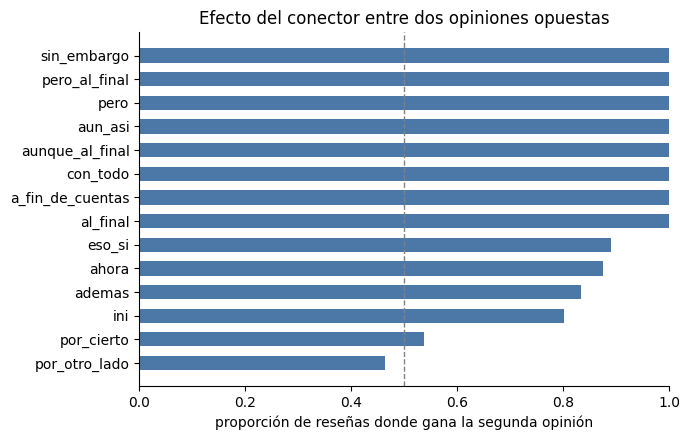

In [21]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(tabla_con.index, tabla_con['% gana la 2da opinión'], color='#4C78A8', height=0.6)
ax.axvline(0.5, color='gray', lw=1, ls='--')
ax.set_xlim(0, 1)
ax.set_xlabel('proporción de reseñas donde gana la segunda opinión')
ax.set_title('Efecto del conector entre dos opiniones opuestas')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

Se ven tres grupos: conectores "de cierre" (*aun así, al final, con todo, sin embargo, pero...*) donde gana la segunda opinión el 100% de las veces; conectores como *eso sí*, *además* o *ahora*, y el caso sin conector (`ini`), donde la segunda gana la mayoría de las veces pero no siempre; y *por otro lado* / *por cierto*, donde queda prácticamente 50/50 (son pocos casos en esta muestra, pero en el resto de los datos vimos lo mismo). Leyendo esos casos nos pareció que ahí pesa la intensidad de cada expresión (*"me decepcionó de principio a fin"* pesa más que *"no vale lo que cuesta"*), y en parte puede ser simplemente ruido en las etiquetas.

Con las probabilidades por cláusula construimos features "estructurales" de cada reseña:
- número de cláusulas, número de opiniones, cuántas positivas/negativas, suma de polaridades, polaridad máxima y mínima;
- para las últimas 4 cláusulas con opinión: su polaridad, qué tan lejos están del final y qué conector las rige;
- polaridad y conector de la primera opinión, y la polaridad de la última cláusula.

In [22]:
def features_clausulas(lista_segs, probas, K=4):
    filas = []
    for segs, q in zip(lista_segs, probas):
        n = len(segs)
        pol = q[:, 2] - q[:, 0]      # >0 positivo, <0 negativo
        opi = 1 - q[:, 1]            # qué tanto parece opinión y no relleno
        f = {'n_clausulas': n, 'suma_pol': pol.sum(), 'max_opi': opi.max(),
             'pol_max': pol.max(), 'pol_min': pol.min(), 'n_opiniones': (opi > 0.5).sum(),
             'n_pos': (pol > 0.5).sum(), 'n_neg': (pol < -0.5).sum()}
        ops = [j for j in range(n) if opi[j] > 0.5] or [int(opi.argmax())]
        ultimas = ops[-K:]
        ultimas = [None] * (K - len(ultimas)) + ultimas   # alineadas a la derecha
        for r, j in enumerate(ultimas):
            f[f'op{r}_pol'] = pol[j] if j is not None else 0
            f[f'op{r}_dist_final'] = (n - 1 - j) if j is not None else -1
            f[f'op{r}_con'] = ETIQUETAS_CON.index(conector_de(segs, j)) if j is not None else -1
        f['primera_pol'] = pol[ops[0]]
        f['primera_con'] = ETIQUETAS_CON.index(conector_de(segs, ops[0]))
        f['ult_clausula_pol'] = pol[-1]
        f['ult_clausula_opi'] = opi[-1]
        filas.append(f)
    return pd.DataFrame(filas)

features_clausulas([segs_train[i] for i in idx_te[:3]], probs_te[:3]).T

,0,1,2
n_clausulas,4.000000,4.000000,4.000000
suma_pol,0.438306,0.558523,-0.605954
max_opi,0.997063,0.998492,0.994694
pol_max,0.858963,0.900506,0.381259
pol_min,-0.490779,-0.832854,-0.979510
n_opiniones,2.000000,3.000000,1.000000
n_pos,1.000000,2.000000,0.000000
n_neg,0.000000,1.000000,1.000000
op0_pol,0.000000,0.000000,0.000000
op0_dist_final,-1.000000,-1.000000,-1.000000


## 7. Modelo final: stacking

Juntamos todo en un solo estimador de scikit-learn:

**Nivel 1 (modelos base):**
- 5 regresiones logísticas TF-IDF (1-2 gramas), cada una sobre una "vista" del texto: texto completo, última oración, última cláusula, últimas 2 cláusulas y segunda mitad del texto. Cada una aporta 3 probabilidades.
- El modelo de cláusulas de la sección 6, del que salen las features estructurales.

**Nivel 2 (meta-modelo):** un `HistGradientBoostingClassifier` que recibe las 15 probabilidades + las features estructurales. Usamos un modelo de árboles porque necesitamos interacciones (por ejemplo "si el conector es *aun así*, hacerle caso a la polaridad de la última opinión"), que una regresión logística no captura. Las columnas de conector se le pasan como categóricas.

Para que el meta-modelo no aprenda de predicciones "demasiado buenas", las features de nivel 1 para entrenar se calculan **fuera de fold** (cada reseña se predice con modelos que no la vieron). Para predecir eval se usan los modelos base reentrenados con todo train.

In [23]:
def vistas_texto(textos_norm, lista_segs):
    v = pd.DataFrame({'completo': list(textos_norm)})
    v['ult_oracion'] = [(oraciones(t) or [t])[-1] for t in textos_norm]
    v['ult_clausula'] = [s[-1][1] for s in lista_segs]
    v['ult_2_clausulas'] = [' '.join(c for _, c in s[-2:]) for s in lista_segs]
    v['seg_mitad'] = [' '.join(t.split()[len(t.split()) // 2:]) for t in textos_norm]
    return v


class ClasificadorSentimiento(BaseEstimator, ClassifierMixin):

    def __init__(self, n_folds=5, C_vistas=10, learning_rate=0.05, max_iter=400,
                 max_leaf_nodes=31, random_state=42):
        self.n_folds = n_folds
        self.C_vistas = C_vistas
        self.learning_rate = learning_rate
        self.max_iter = max_iter
        self.max_leaf_nodes = max_leaf_nodes
        self.random_state = random_state

    def _preparar(self, X):
        textos = [normalizar(t) for t in X]
        segs = [segmentar(t) for t in textos]
        return segs, vistas_texto(textos, segs)

    def _ajustar_base(self, segs, vistas, y):
        claus = ModeloClausulas().fit(segs, y)
        lrs = {c: tfidf_lr(self.C_vistas).fit(vistas[c], y) for c in vistas.columns}
        return claus, lrs

    def _meta(self, claus, lrs, segs, vistas):
        F = features_clausulas(segs, claus.probas_por_resena(segs))
        for c, m in lrs.items():
            p = m.predict_proba(vistas[c])
            for k, clase in enumerate(m.classes_):
                F[f'lr_{c}_{clase}'] = p[:, k]
        return F

    def meta_features_oof(self, X, y):
        # features de nivel 1 calculadas fuera de fold
        y = np.asarray(y)
        segs, vistas = self._preparar(X)
        skf = StratifiedKFold(self.n_folds, shuffle=True, random_state=self.random_state)
        bloques = []
        for tr, te in skf.split(vistas, y):
            claus, lrs = self._ajustar_base([segs[i] for i in tr], vistas.iloc[tr], y[tr])
            F = self._meta(claus, lrs, [segs[i] for i in te], vistas.iloc[te].reset_index(drop=True))
            F.index = te
            bloques.append(F)
        return pd.concat(bloques).sort_index(), segs, vistas

    def _nuevo_meta(self, columnas):
        cat = [i for i, c in enumerate(columnas) if c.endswith('_con')]
        return HistGradientBoostingClassifier(
            learning_rate=self.learning_rate, max_iter=self.max_iter,
            max_leaf_nodes=self.max_leaf_nodes, categorical_features=cat,
            early_stopping=False, random_state=self.random_state)

    def fit(self, X, y):
        y = np.asarray(y)
        F, segs, vistas = self.meta_features_oof(X, y)
        self.claus_, self.lrs_ = self._ajustar_base(segs, vistas, y)
        self.meta_ = self._nuevo_meta(list(F.columns)).fit(F, y)
        self.classes_ = self.meta_.classes_
        self.columnas_ = list(F.columns)
        return self

    def predict_proba(self, X):
        segs, vistas = self._preparar(X)
        F = self._meta(self.claus_, self.lrs_, segs, vistas)[self.columnas_]
        return self.meta_.predict_proba(F)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]

### Evaluación honesta (validación cruzada anidada)

Como el modelo ya hace sus propios folds por dentro, para estimar su desempeño real lo metemos completo dentro de otra validación cruzada de 5 folds (folds distintos a los internos). Así ninguna reseña de validación se usa en ningún paso del entrenamiento. Tarda un par de minutos.

In [24]:
cv_externa = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
scores_final = cross_val_score(ClasificadorSentimiento(), train.text, y, cv=cv_externa, n_jobs=-1)
print('accuracy por fold:', np.round(scores_final, 4))
print(f'promedio: {scores_final.mean():.4f} (+/- {scores_final.std():.4f})')

accuracy por fold: [0.9129 0.9046 0.9029 0.8992 0.9071]
promedio: 0.9053 (+/- 0.0046)


Pasamos de ~89% a ~90.5%. Antes de este modelo hicimos un **cuarto envío** con una versión intermedia: el mismo stacking pero sin las features de cláusulas (solo las 5 vistas TF-IDF), para medir cuánto aportaban las features estructurales.

In [25]:
modelo_aux = ClasificadorSentimiento()
F_oof, segs_full, vistas_full = modelo_aux.meta_features_oof(train.text, y)
cols_vistas = [c for c in F_oof.columns if c.startswith('lr_')]

s = cross_val_score(HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, early_stopping=False,
                                                   random_state=SEMILLA),
                    F_oof[cols_vistas], y, cv=CV, n_jobs=-1)
print(f'stacking solo con vistas TF-IDF: {s.mean():.4f}')
s = cross_val_score(modelo_aux._nuevo_meta(list(F_oof.columns)), F_oof, y, cv=CV, n_jobs=-1)
print(f'stacking vistas + features de cláusulas: {s.mean():.4f}')

stacking solo con vistas TF-IDF: 0.8975


stacking vistas + features de cláusulas: 0.9050


In [26]:
# envío 4: stacking solo con las vistas TF-IDF
claus_full, lrs_full = modelo_aux._ajustar_base(segs_full, vistas_full, y)
segs_ev = [segmentar(t) for t in eval_norm]
F_eval = modelo_aux._meta(claus_full, lrs_full, segs_ev, vistas_texto(eval_norm, segs_ev))[F_oof.columns]

meta_vistas = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, early_stopping=False,
                                             random_state=SEMILLA).fit(F_oof[cols_vistas], y)
guardar_envio(meta_vistas.predict(F_eval[cols_vistas]), '04_stacking_solo_vistas')

envios/04_stacking_solo_vistas.csv {'positivo': np.int64(1112), 'negativo': np.int64(1062), 'neutral': np.int64(826)}


### Ajuste de hiperparámetros del meta-modelo

Probamos algunas combinaciones de `learning_rate`, `max_iter` y `max_leaf_nodes` sobre las features fuera de fold (que ya calculamos arriba, así no hay que reentrenar los modelos base cada vez). No hicimos una búsqueda enorme porque las diferencias son pequeñas.

In [27]:
grilla = [(lr, it, hojas) for lr, it in [(0.1, 200), (0.05, 400), (0.03, 600), (0.02, 1000)]
          for hojas in [15, 31]]
res_grid = []
for lr, it, hojas in grilla:
    m = HistGradientBoostingClassifier(learning_rate=lr, max_iter=it, max_leaf_nodes=hojas,
                                       categorical_features=[i for i, c in enumerate(F_oof.columns) if c.endswith('_con')],
                                       early_stopping=False, random_state=SEMILLA)
    s = cross_val_score(m, F_oof, y, cv=CV, n_jobs=-1)
    res_grid.append({'learning_rate': lr, 'max_iter': it, 'max_leaf_nodes': hojas, 'accuracy': s.mean(), 'std': s.std()})
res_grid = pd.DataFrame(res_grid).sort_values('accuracy', ascending=False)
res_grid

,learning_rate,max_iter,max_leaf_nodes,accuracy,std
1,0.10,200,31,0.905500,0.001000
7,0.02,1000,31,0.905167,0.004934
6,0.02,1000,15,0.905083,0.002892
5,0.03,600,31,0.905000,0.004944
3,0.05,400,31,0.905000,0.004175
2,0.05,400,15,0.904667,0.002318
0,0.10,200,15,0.904583,0.002514
4,0.03,600,15,0.903833,0.003841


### Errores que quedan

              precision    recall  f1-score   support

    negativo      0.867     0.867     0.867      4212
     neutral      0.997     0.998     0.997      3576
    positivo      0.866     0.865     0.866      4212

    accuracy                          0.905     12000
   macro avg      0.910     0.910     0.910     12000
weighted avg      0.905     0.905     0.905     12000



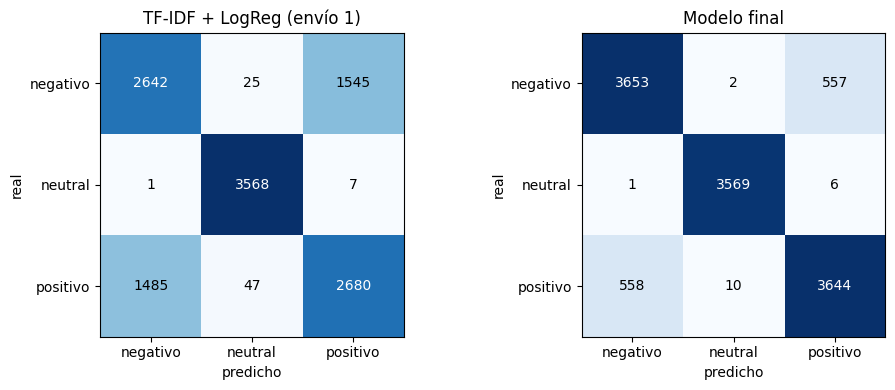

In [28]:
mejor = res_grid.iloc[0]
meta_cv = HistGradientBoostingClassifier(learning_rate=mejor.learning_rate, max_iter=int(mejor.max_iter),
                                         max_leaf_nodes=int(mejor.max_leaf_nodes),
                                         categorical_features=[i for i, c in enumerate(F_oof.columns) if c.endswith('_con')],
                                         early_stopping=False, random_state=SEMILLA)
pred_final = cross_val_predict(meta_cv, F_oof, y, cv=CV, n_jobs=-1)
print(classification_report(y, pred_final, digits=3))

clases = ['negativo', 'neutral', 'positivo']
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (titulo, p) in zip(ax, [('TF-IDF + LogReg (envío 1)', pred_base), ('Modelo final', pred_final)]):
    cm = confusion_matrix(y, p, labels=clases)
    a.imshow(cm, cmap='Blues')
    a.set_xticks(range(3), clases)
    a.set_yticks(range(3), clases)
    a.set_xlabel('predicho')
    a.set_ylabel('real')
    a.set_title(titulo)
    for i in range(3):
        for j in range(3):
            a.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.show()

In [29]:
mal = np.where(pred_final != y)[0]
for i in np.random.RandomState(5).choice(mal, 5, replace=False):
    print(f'[real: {y[i]} | predicho: {pred_final[i]}]')
    print(train.text[i], '\n')

[real: positivo | predicho: negativo]
Desde que lo compré, lo compré para reemplazar otro. Estoy feliz con la instalación. De paso, terminé harto del empaque. 

[real: positivo | predicho: negativo]
Lo pedí a mediados de mes y llegó en cuatro días a mi casa, en caja cerrada. Desde entonces lo tengo funcionando casi sin parar, lo uso a diario en la oficina. La autonomía no es para nada lo que esperaba según las indicaciones que venían en la descripción. Por cierto, me alegra haber elegido el botón de encendido, lo pedí así cuando hice el pedido. Todavía no sé qué tan seguido le voy a dar uso en los meses que vienen. 

[real: negativo | predicho: positivo]
Compré este ventilador a principios de año porque en mi cuarto hace mucho calor en las tardes, y la verdad el ventilador fue una fuente continua de problemas. El envío tardó como cuatro días y llegó en caja normal, nada raro. Lo tenía encima de la cómoda junto a la cama, conectado al enchufe de al lado, y nunca me funcionó como esperab

Los errores entre positivo y negativo bajaron de unos 3.000 (envío 1) a unos 1.100. Lo que queda son sobre todo reseñas con dos opiniones opuestas unidas por conectores "ambiguos" (*eso sí, por otro lado, por cierto*), donde ni la posición ni el conector deciden, y algunas cláusulas con adjetivos raros que el modelo de polaridad no conoce bien (*"el diseño terminó siendo lentísimo"*). Es justamente el tipo de cosas que un modelo secuencial de la Parte 2 debería manejar mejor.

## 8. Entrenamiento final, guardado del modelo y archivo de envío

Entrenamos el modelo con todo train y los mejores hiperparámetros, lo guardamos con `joblib` y generamos el archivo para Kaggle.

**Nota para cargar el modelo:** el archivo `.joblib` guarda objetos de las clases definidas en este notebook (`ClasificadorSentimiento`, `ModeloClausulas`) y usa las funciones de preprocesamiento, así que antes de hacer `joblib.load` hay que ejecutar las celdas de imports y de definiciones (secciones 1, 2, 4, 5, 6 y 7). Después basta con `modelo.predict(lista_de_textos)` pasando el texto original, sin normalizar.

In [30]:
modelo_final = ClasificadorSentimiento(learning_rate=float(mejor.learning_rate), max_iter=int(mejor.max_iter),
                                       max_leaf_nodes=int(mejor.max_leaf_nodes), random_state=SEMILLA)
modelo_final.fit(train.text, y)
joblib.dump(modelo_final, 'modelo_final.joblib')
modelo_final

,learning_rate,0.1
,max_iter,200
,n_folds,5
,C_vistas,10
,max_leaf_nodes,31
,random_state,42
Name,Type,Value
classes_,"ndarray[object](3,)","['negativo','neutral','positivo']"
claus_,ModeloClausulas,<__main__.Mod...001BADE11E6D0>
columnas_,list,"['n_...as', 'su...ol', 'max_opi', 'pol_max', ...]"
lrs_,dict,"{'co...to': Pipeline(step..._iter=3000))]), 'se...ad': Pipeline(step..._iter=3000))]), 'ul...as': Pipeline(step..._iter=3000))]), 'ul...la': Pipeline(step..._iter=3000))]), ...}"


In [31]:
# verificamos que el modelo guardado se carga y predice lo mismo
modelo_cargado = joblib.load('modelo_final.joblib')
pred_eval = modelo_cargado.predict(evaluacion.text)
print('Coincide con el modelo en memoria:', (pred_eval == modelo_final.predict(evaluacion.text)).all())
guardar_envio(pred_eval, '05_modelo_final')
pd.read_csv('envios/05_modelo_final.csv').head()

Coincide con el modelo en memoria: True
envios/05_modelo_final.csv {'positivo': np.int64(1118), 'negativo': np.int64(1056), 'neutral': np.int64(826)}


,id,answer
0,0,neutral
1,1,positivo
2,2,neutral
3,3,neutral
4,4,neutral


## 9. Conclusiones

Resumen de las iteraciones (accuracy en validación cruzada de 5 folds sobre train):

| Envío | Modelo | Accuracy CV |
|---|---|---|
| 1 | TF-IDF 1-2 gramas + regresión logística | ~0.741 |
| 2 | TF-IDF texto completo + TF-IDF última oración | ~0.885 |
| 3 | + TF-IDF de la última cláusula | ~0.891 |
| 4 | Stacking de 5 vistas TF-IDF con HistGradientBoosting | ~0.898 |
| 5 | Stacking de vistas + features de cláusulas (modelo final) | ~0.905 (CV anidada) |

Lo más importante que aprendimos:
- Una bolsa de palabras sobre todo el texto pierde el orden, y en este problema el orden es casi todo: solo con la última oración se gana más que con el texto completo.
- Sin salirnos de TF-IDF y modelos clásicos se puede recuperar parte de esa información "a mano": aplicando el vectorizador sobre partes específicas del texto y extrayendo features de la secuencia de opiniones.
- La interacción entre el conector y la polaridad de cada opinión no es lineal, por eso el meta-modelo de árboles le gana a la regresión logística.
- Limitaciones: la lista de conectores la armamos nosotros mirando los datos (si en eval aparecen otros, no se detectan como conectores), y la segmentación por reglas es simple. Los casos con conectores ambiguos siguen siendo difíciles y probablemente necesiten un modelo que lea la secuencia completa.